# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Anh Bach, Annie Nguyen, Sritha Alluri

**Date:** 11/02/2026

In [1]:
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

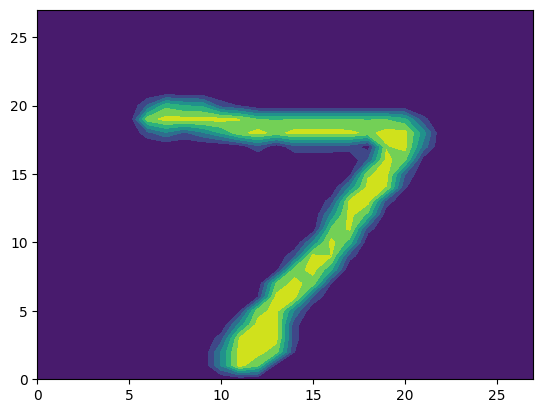

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

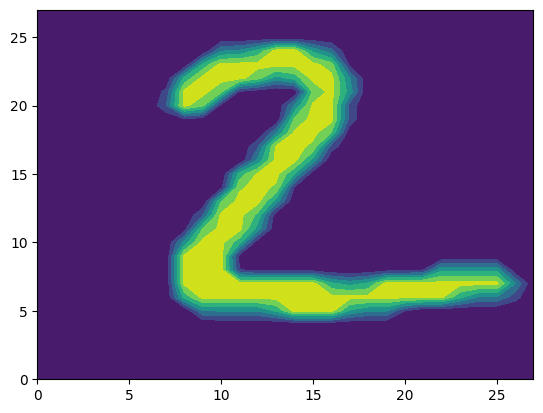

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

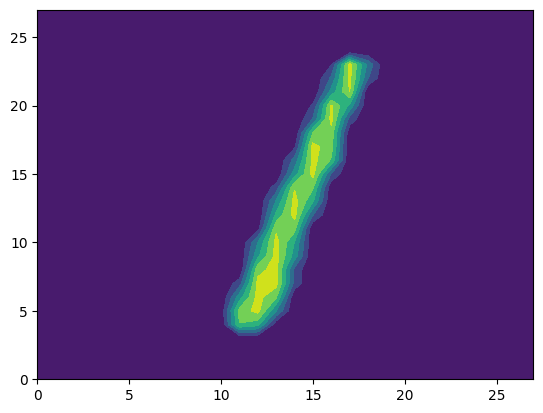

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

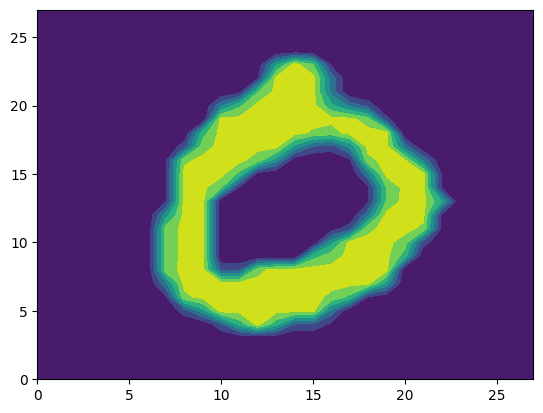

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

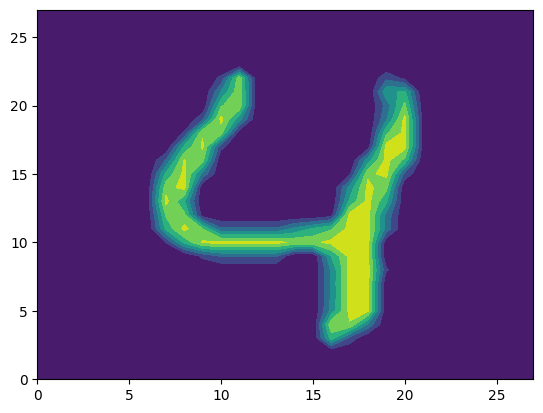

In [2]:
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

In [3]:
#Q2 Answers
print(X_train.shape)
print(X_test.shape)
print(X_train[0].shape)
print(X_test[0].shape)
print(y_train.shape)
print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(28, 28)
(28, 28)
(60000,)
(10000,)


Q2 Explanation: X_train has shape (60000, 28, 28) and X_test has shape (10000, 28, 28). The first number is how many images there are, so we have 60,000 images to train on and 10,000 images to test on. The other two numbers are the size of each image. So each X_train[i] and X_test[i] has shape (28, 28), which means one image is a 28 by 28 grid of numbers. y_train has shape (60000,) and y_test has shape (10000,), so there is one digit label for each image.

In [4]:
#Q3 Answers 

N_train = len(X_train)
X = np.zeros((N_train, 784))
for i in range(N_train):
    X[i] = X_train[i].reshape((1, 784))

N_test = len(X_test)
X_test_flat = np.zeros((N_test, 784))
for i in range(N_test):
    X_test_flat[i] = X_test[i].reshape((1, 784))

print("Training:", X.shape)
print("Test:", X_test_flat.shape)

Training: (60000, 784)
Test: (10000, 784)


Q3 Explanation: We used a for loop to flatten each 28 by 28 image into a row of 784 pixel values. Now X is (60000, 784) and X_test_flat is (10000, 784), so each row is one image and each column is one pixel.

k = 1 Accuracy: 0.9691
k = 2 Accuracy: 0.9627
k = 3 Accuracy: 0.9705
k = 4 Accuracy: 0.9682
k = 5 Accuracy: 0.9688
k = 6 Accuracy: 0.9677
k = 7 Accuracy: 0.9694
k = 8 Accuracy: 0.967
k = 9 Accuracy: 0.9659
k = 10 Accuracy: 0.9665


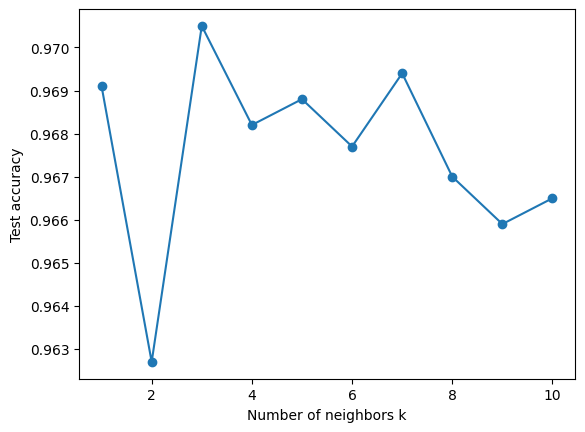

In [5]:
#Q4 Answers 

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = range(1, 11)
accuracies = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors = k)
    model.fit(X, y_train)
    y_hat = model.predict(X_test_flat)
    accuracies.append(accuracy_score(y_test, y_hat))
    print("k =", k, "Accuracy:", round(accuracies[-1], 4))

plt.plot(k_values, accuracies, marker = "o")
plt.xlabel("Number of neighbors k")
plt.ylabel("Test accuracy")
plt.show()

Q4 Explanation: We made a kNN classifier using the reshaped training data X and checked it on X_test_flat and y_test. We tried k from 1 to 10. The highest recorded test accuracy was 0.9705 (97.05%) at k = 3, so we selected k = 3 as the best among the values tested. The test accuracies ranged from 0.9627 to 0.9705. Because we used the test set to choose k, this score is not an independent final evaluation and may be optimistic. Ideally, we would select k using a validation set or cross-validation on the training data, then evaluate the selected model once on the test set.

In [10]:
#Q5 Answers

from sklearn.metrics import confusion_matrix

model = KNeighborsClassifier(n_neighbors = 3)
model.fit(X, y_train)
y_hat = model.predict(X_test_flat)

print("Accuracy:", accuracy_score(y_test, y_hat))
cm = confusion_matrix(y_test, y_hat)
print(cm)

for digit in range(10):
    print("Digit", digit, "recall:", round(cm[digit, digit] / cm[digit].sum(), 4))

Accuracy: 0.9705
[[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [  10    9  996    2    0    0    0   13    2    0]
 [   0    2    4  976    1   13    1    7    3    3]
 [   1    6    0    0  950    0    4    2    0   19]
 [   6    1    0   11    2  859    5    1    3    4]
 [   5    3    0    0    3    3  944    0    0    0]
 [   0   21    5    0    1    0    0  991    0   10]
 [   8    2    4   16    8   11    3    4  914    4]
 [   4    5    2    8    9    2    1    8    2  968]]
Digit 0 recall: 0.9939
Digit 1 recall: 0.9982
Digit 2 recall: 0.9651
Digit 3 recall: 0.9663
Digit 4 recall: 0.9674
Digit 5 recall: 0.963
Digit 6 recall: 0.9854
Digit 7 recall: 0.964
Digit 8 recall: 0.9384
Digit 9 recall: 0.9594


Q5 Explanation: With k = 3, the model correctly classified 9,705 of the 10,000 test images, giving an overall accuracy of 0.9705 (97.05%) and 295 mistakes. In the confusion matrix, each row is the actual digit and each column is the predicted digit. The diagonal contains correct predictions, and most counts fall there. The per-digit calculation is recall: the fraction of images of an actual digit that were classified correctly. Recall is highest for 1 (0.9982) and 0 (0.9939), and lowest for 8 (0.9384) and 9 (0.9594). Thus, the model misses a larger proportion of actual 8s and 9s. As noted in Q4, this test set was also used to select k.

Q6 Explanation: The most common mistakes are 7 being read as 1 (21 times), 4 as 9 (19 times), and 8 as 3 (16 times). The model seems to mix up numbers that can look similar when handwritten, like 3 and 5. The mistakes do not always go both ways: 21 actual 7s were read as 1, but no 1s were read as 7. Overall, 8 has the highest error rate, with about 6.16% of actual 8s classified incorrectly.

Q7 Explanation: We could represent a color photo using three matrices, one for red, one for green, and one for blue. Each pixel would have three values from 0 to 255 showing how much of each color it has. A 28 by 28 color photo would have shape (28, 28, 3). We could flatten it into one row with 2,352 features. In a table, each row would be one photo and each column would be a color value at a specific pixel. All photos would need the same size and the same order of pixel and color values.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 17340cca5b8c4084d90842fd89789f19630a67b8
- **AI tool and model used:** ChatGPT

### *Prompts used

1. check question 1
2. check question 2
3. check question 3
4. check question 4
5. "Check questions 1-7 given assignment questions and output. Flag any redundancies or room for improvement."
6. "Produce a numbered list of suggestions, if any."

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Question 1 looks correct. It loads the data, assigns the training and test arrays, and displays five digits with their labels, pixel matrices, and plots. The saved output has all five plots and no errors. The instructions say “first ten,” but their example uses `range(5)`, which your code follows. Use `range(10)` if you want to match the written wording; otherwise, no changes are needed.

2. Question 2 in the saved notebook is correct and complete. The code prints all six requested shapes, and the explanation correctly describes the images and labels. No changes needed.

3. I checked the code: it correctly reshapes both datasets and uses the variable names needed for your later questions

4. Yes—it’s correct for the assignment’s option to try different \(k\) values. It trains on the training data, compares \(k=1\) through \(10\), and selects the highest accuracy. Your saved results show \(k=3\), with 97.05% accuracy. The explanation also correctly notes that choosing \(k\) using the test set makes that score less reliable as an independent evaluation.

5. Keep as written. Optionally clarify that recall measures how often the model correctly identifies each actual digit.

6. Replace the 3-versus-5 example with an actual finding from your confusion matrix, such as 7 being mistaken for 1. Add a brief explanation that similar handwritten shapes may cause misclassification.

7. Clarify that RGB values represent the intensity of red, green, and blue at each pixel.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Checked to range(10) to make sure we correctly follow the instructions. |
| 2 | Reject | Nothing to modify |
| 3 | Reject | Nothing to modify |
| 4 | Reject | Nothing to modify |
| 5 | Reject | Nothing to modify |
| 6 | Accept | Replaced the 3-versus-5 example with actual findings from the confusion matrix and added explanations for why visually similar handwritten digits may be misclassified. |
| 7 | Accept | Clarified that RGB values represent the intensity of each color channel and connected the flattening process to the method used in Q3. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

**Q1**

In [ ]:
import pickle
import matplotlib.pyplot as plt
import numpy as np

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)

X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

np.set_printoptions(edgeitems=30, linewidth=100000)

for i in range(10):
    print(y_test[i], '\n')
    print(X_test[i], '\n')
    plt.contourf(np.rot90(X_test[i].transpose()))
    plt.show()

**Q2**

In [ ]:
# Q2
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_train[i]:", X_train[0].shape)
print("X_test[i]:", X_test[0].shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Q2 Explanation: X_train has shape (60000, 28, 28) and X_test has shape (10000, 28, 28). The first number is how many images there are, so we have 60,000 images to train on and 10,000 images to test on. The other two numbers are the size of each image. So each X_train[i] and X_test[i] has shape (28, 28), which means one image is a 28 by 28 grid of numbers. y_train has shape (60000,) and y_test has shape (10000,), so there is one digit label for each image.

**Q3**

In [ ]:
# Q3
X = X_train.reshape(len(X_train), 784)
X_test_flat = X_test.reshape(len(X_test), 784)

print("Training:", X.shape)
print("Test:", X_test_flat.shape)

Q3 Explanation: We used reshape to flatten each 28 by 28 image into a row of 784 pixel values. Now X is (60000, 784) and X_test_flat is (10000, 784), so each row is one image and each column is one pixel.

**Q4**

In [ ]:
# Q4
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = range(1, 11)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X, y_train)
    y_hat = model.predict(X_test_flat)
    accuracies.append(accuracy_score(y_test, y_hat))
    print("k =", k, "Accuracy:", round(accuracies[-1], 4))

best_k = list(k_values)[np.argmax(accuracies)]
print("Best k tested:", best_k)

plt.plot(k_values, accuracies, marker="o")
plt.xlabel("Number of neighbors k")
plt.ylabel("Test accuracy")
plt.show()

Q4 Explanation: We tried k values from 1 to 10. The highest test accuracy was 0.9705 (97.05%) at k = 3, so it was the best value we tested. The scores were all fairly close. Since we used the test set to choose k, the accuracy may be optimistic. Ideally, we would choose k using validation data and then check the final model on the test set.

**Q5**

In [ ]:
from sklearn.metrics import confusion_matrix

model = KNeighborsClassifier(n_neighbors = 3)
model.fit(X, y_train)
y_hat = model.predict(X_test_flat)

print("Accuracy:", accuracy_score(y_test, y_hat))
cm = confusion_matrix(y_test, y_hat)
print(cm)

for digit in range(10):
    print("Digit", digit, "recall:", round(cm[digit, digit] / cm[digit].sum(), 4))

With k = 3, the model correctly classified 9,705 of the 10,000 test images, giving an overall accuracy of 0.9705 (97.05%) and 295 mistakes. In the confusion matrix, each row is the actual digit and each column is the predicted digit. The diagonal contains correct predictions, and most counts fall there. The per-digit calculation is recall: the fraction of images of an actual digit that were classified correctly. Recall is highest for 1 (0.9982) and 0 (0.9939), and lowest for 8 (0.9384) and 9 (0.9594). Thus, the model misses a larger proportion of actual 8s and 9s. As noted in Q4, this test set was also used to select k.

**Q6**

The most common mistakes are 7 being classified as 1 (21 times), 4 as 9 (19 times), and 8 as 3 (16 times). These mistakes may occur because certain handwritten digits have similar visual features. For example, a handwritten 7 without a clear crossbar may resemble a 1, while an 8 with an unclear lower loop may resemble a 3. The mistakes are also not necessarily symmetrical. For example, 21 actual 7s were classified as 1, but no actual 1s were classified as 7. Overall, 8 has the highest error rate, with approximately 6.16% of actual 8s classified incorrectly. This suggests that some digits are more difficult for the classifier to distinguish based on their pixel patterns.

**Q7**

We could represent a color photo using three matrices, one for red, one for green, and one for blue. Each pixel would have three values from 0 to 255 representing the intensity of each color channel. A 28 by 28 color photo would therefore have a shape of (28, 28, 3). Similar to what we did with the MNIST data in Q3, we could flatten this into one row with 2,352 features (28 × 28 × 3). In a table, each row would represent one photo and each column would represent a specific color channel at a specific pixel location. All photos would need to have the same dimensions and the same order of pixel and color values.

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements focused on making the written explanations more precise and ensuring they accurately reflected the code and outputs. For Q6, we focused the explanation on the most frequent mistakes in the confusion matrix, including 7 being classified as 1 (21 times), 4 as 9 (19 times), and 8 as 3 (16 times). We also added an explanation of how similarities in handwritten digit shapes may contribute to misclassification. For Q7, we clarified that RGB values represent the intensity of red, green, and blue channels and connected the flattening process to the method used in Q3. One AI limitation was that it described the 3-versus-5 example as unsupported, even though the confusion matrix shows mistakes in both directions. This highlighted the importance of checking AI suggestions against the actual outputs. The final solution was verified by reviewing the code, accuracy calculations, confusion matrix, and written explanations for consistency. The code and numerical results were retained because they were already correct. One remaining concern is that the optimal value of k was selected using the test set rather than a separate validation set, which could introduce some evaluation bias.